## Interval Analysis

In [1]:
# !pip install tensorboardX

import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
import numpy as np
import time
import matplotlib.pyplot as plt

from torchvision import datasets, transforms
# from tensorboardX import SummaryWriter

use_cuda = False
device = torch.device("cuda" if use_cuda else "cpu")
batch_size = 64

np.random.seed(42)
torch.manual_seed(42)


## Dataloaders
train_dataset = datasets.MNIST('mnist_data/', train=True, download=True, transform=transforms.Compose(
    [transforms.ToTensor()]
))
test_dataset = datasets.MNIST('mnist_data/', train=False, download=True, transform=transforms.Compose(
    [transforms.ToTensor()]
))

train_loader = torch.utils.data.DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader = torch.utils.data.DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

## Simple NN. You can change this if you want. If you change it, mention the architectural details in your report.
class Net(nn.Module):
    def __init__(self):
        super(Net, self).__init__()
        self.fc = nn.Linear(28*28, 200)
        self.fc2 = nn.Linear(200,10)

    def forward(self, x):
        x = x.view((-1, 28*28))
        x = F.relu(self.fc(x))
        x = self.fc2(x)
        x = F.softmax(x, dim=-1) # added softmax for probabilities
        return x

class Normalize(nn.Module):
    def forward(self, x):
        return (x - 0.1307)/0.3081

# Add the data normalization as a first "layer" to the network
# this allows us to search for adverserial examples to the real image, rather than
# to the normalized image
model = nn.Sequential(Normalize(), Net())

model = model.to(device)
model.train()


100%|██████████| 9.91M/9.91M [00:01<00:00, 4.97MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 131kB/s]
100%|██████████| 1.65M/1.65M [00:01<00:00, 1.24MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 6.19MB/s]


Sequential(
  (0): Normalize()
  (1): Net(
    (fc): Linear(in_features=784, out_features=200, bias=True)
    (fc2): Linear(in_features=200, out_features=10, bias=True)
  )
)

In [2]:
def train_model(model, num_epochs):
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.SGD(model.parameters(), lr=0.001, momentum=0.9)

    for epoch in range(num_epochs):
        model.train()
        running_loss = 0.0
        for i, data in enumerate(train_loader, 0):
            images, labels = data
            images, labels = images.to(device), labels.to(device)

            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item()

        print(f'Epoch {epoch+1}/{num_epochs}, Loss: {running_loss/len(train_loader):.3f}')

def test_model(model):
    model.eval()
    with torch.no_grad():
        correct = 0
        total = 0
        for data in test_loader:
            images, labels = data
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            _, predicted = torch.max(outputs.data, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()
        print(f'Accuracy on images: {100 * correct / total}')

In [3]:
# train_model(model, 10)
# test_model(model)

### Write the interval analysis for the simple model

In [4]:
## TODO: Write the interval analysis for the simple model
## you can use https://github.com/Zinoex/bound_propagation

## HW4 Q1

In [5]:
%pip install -q bound-propagation==0.4.5

In [6]:
import copy
from bound_propagation import BoundModelFactory, HyperRectangle

class IBP(nn.Module):
    def __init__(self):
        super().__init__()
        self.hidden = nn.Sequential(
            nn.Linear(784, 50), nn.ReLU(),
            nn.Linear(50, 50), nn.ReLU(),
            nn.Linear(50, 50), nn.ReLU())
        self.last = nn.Linear(50, 10)

    def forward(self, x):
        return self.last(self.hidden(x.flatten(1)))  # Raw logits, no softmax.

def input_box(x, eps):
    x = x.flatten(1)
    return HyperRectangle((x - eps).clamp(0, 1), (x + eps).clamp(0, 1))

def worst_logits(net, bound_hidden, x, y, eps):
    h = bound_hidden.ibp(input_box(x, eps))
    center, radius = (h.lower + h.upper) / 2, (h.upper - h.lower) / 2
    # Eq. (9): U_j >= z_j - z_y, U_y = 0; CE(U,y) is the robust loss.
    w = net.last.weight[None] - net.last.weight[y][:, None]
    b = net.last.bias[None] - net.last.bias[y][:, None]
    upper = (w * center[:, None]).sum(-1) + (w.abs() * radius[:, None]).sum(-1) + b
    return upper.scatter(1, y[:, None], 0.0)

/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


In [7]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(device)
epochs, warmup_epochs, ramp_epochs = 60, 0, 60

torch.manual_seed(42)
model = IBP()

def synchronize():
    if device.type == 'cuda':
        torch.cuda.synchronize()

def train_ibp(use_ibp):
    net = copy.deepcopy(model).to(device)
    bound_hidden = BoundModelFactory().build(net.hidden)
    optimizer = optim.Adam(net.parameters(), lr=5e-4)
    scheduler = optim.lr_scheduler.MultiStepLR(optimizer, milestones=[45, 55], gamma=0.2)
    # Warm up kernels without updating weights; downloading/evaluation are not timed.
    x, y = next(iter(train_loader))
    x, y = x.to(device), y.to(device)
    warm_loss = F.cross_entropy(net(x), y)
    if use_ibp:
        warm_loss = warm_loss + F.cross_entropy(worst_logits(net, bound_hidden, x, y, 0.01), y)
    warm_loss.backward()
    optimizer.zero_grad(set_to_none=True)
    torch.manual_seed(2026)  # Same initialization and minibatch order for both runs.
    synchronize()
    started = time.perf_counter()
    if use_ibp: print("IBP")
    else: print("Standard")
    for epoch in range(epochs):
        net.train()
        for batch, (x, y) in enumerate(train_loader):
            x, y = x.to(device), y.to(device)
            step = epoch * len(train_loader) + batch
            progress = min(1., max(0., (step - warmup_epochs * len(train_loader)) /
                                  (ramp_epochs * len(train_loader) - 1)))
            eps, weight = (0.1 * progress, 1 - 0.5 * progress) if use_ibp else (0., 1.)
            optimizer.zero_grad(set_to_none=True)
            clean_loss = F.cross_entropy(net(x), y)
            robust_loss = (F.cross_entropy(worst_logits(net, bound_hidden, x, y, eps), y)
                           if use_ibp and weight < 1 else clean_loss)
            loss = weight * clean_loss + (1 - weight) * robust_loss  # Eq. (12).
            loss.backward()
            optimizer.step()
        scheduler.step()
        if (epoch + 1) % 10 == 0 or epoch == 0:
            print(f'epoch {epoch+1}, eps={eps:.3f}, weight={weight:.3f}')
    synchronize()
    seconds = time.perf_counter() - started
    return net.eval(), seconds

standard, standard_seconds = train_ibp(False)
ibp_model, ibp_seconds = train_ibp(True)

print("Training time:")
print(f'standard: {standard_seconds:.6f}s; IBP: {ibp_seconds:.6f}s, IBP time cosuming is {ibp_seconds / standard_seconds:.2f}x')

cpu
Standard
epoch 1, eps=0.000, weight=1.000
epoch 10, eps=0.000, weight=1.000
epoch 20, eps=0.000, weight=1.000
epoch 30, eps=0.000, weight=1.000
epoch 40, eps=0.000, weight=1.000
epoch 50, eps=0.000, weight=1.000
epoch 60, eps=0.000, weight=1.000
IBP
epoch 1, eps=0.002, weight=0.992
epoch 10, eps=0.017, weight=0.917
epoch 20, eps=0.033, weight=0.833
epoch 30, eps=0.050, weight=0.750
epoch 40, eps=0.067, weight=0.667
epoch 50, eps=0.083, weight=0.583
epoch 60, eps=0.100, weight=0.500
Training time:
standard: 653.145352s; IBP: 993.329557s, IBP time cosuming is 1.52x


In [8]:
verify_net = copy.deepcopy(ibp_model).double()
bound_full = BoundModelFactory().build(nn.Sequential(verify_net.hidden, verify_net.last))

@torch.no_grad()
def box_verify(x, y, eps):
    bounds = bound_full.ibp(input_box(x.double(), eps))
    other_upper = bounds.upper.clone().scatter(1, y[:, None], -torch.inf)
    return bounds.lower.gather(1, y[:, None]).squeeze(1) > other_upper.max(1).values + 1e-9

def pgd(net, x, y, eps):
    lower, upper = (x - eps).clamp(0, 1), (x + eps).clamp(0, 1)
    best = x.clone()
    found = torch.zeros(len(y), dtype=torch.bool, device=device)
    for restart in range(6):
        adv = x.clone() if restart == 0 else lower + torch.rand_like(x) * (upper - lower)
        for step in range(51):
            adv = adv.detach().requires_grad_(True)
            logits = net(adv)
            with torch.no_grad():
                wrong = logits.argmax(1).ne(y)
                best[wrong & ~found] = adv.detach()[wrong & ~found]
                found |= wrong
            if bool(found.all()):
                return best.detach()
            if step == 50:
                break
            gradient = torch.autograd.grad(F.cross_entropy(logits, y), adv)[0]
            adv = torch.maximum(torch.minimum(adv + eps / 10 * gradient.sign(), upper), lower)
    return best.detach()

examples, seen_indices = [], set()

def evaluate(net, eps, verify=False, keep_examples=False):
    clean_count = robust_count = certified_count = attacked_count = 0
    offset, kept = 0, 0
    torch.manual_seed(1000 + round(eps * 100))
    for x, y in test_loader:  # Reuse the original HW2 loader, including its batch size.
        x, y = x.to(device), y.to(device)
        with torch.no_grad():
            clean = net(x).argmax(1).eq(y)
            certified = box_verify(x, y, eps) & clean if verify else torch.zeros_like(clean)
        # Certified images have a proof; clean errors already fail robustness at delta=0.
        # Attack all other clean-correct images. The denominator is always all 10,000.
        mask = clean & ~certified
        adv = x.clone()
        if bool(mask.any()):
            adv[mask] = pgd(net, x[mask], y[mask], eps)
        with torch.no_grad():
            predictions = net(adv).argmax(1)
            found = clean & predictions.ne(y)
        assert (adv - x).abs().max() <= eps + 1e-6 and adv.min() >= 0 and adv.max() <= 1
        clean_count += int(clean.sum())
        robust_count += int((clean & ~found).sum())
        certified_count += int(certified.sum())
        attacked_count += int(found.sum())
        if keep_examples:
            for j in found.nonzero(as_tuple=False).flatten().tolist():
                if kept < 2 and offset + j not in seen_indices:
                    examples.append((offset+j, x[j].cpu(), adv[j].cpu(), int(y[j]), int(predictions[j]), eps))
                    seen_indices.add(offset + j)
                    kept += 1
        offset += len(y)
    n = len(test_loader.dataset)
    return {'epsilon': eps, 'clean_accuracy': 100 * clean_count / n,
            'PGD_accuracy': 100 * robust_count / n,
            'verified_accuracy': 100 * certified_count / n,
            'clean_errors': n - clean_count, 'attacks_found': attacked_count,
            'unresolved': clean_count - certified_count - attacked_count}

standard_result = evaluate(standard, 0.1)
results = []
for k in range(1, 11):
    row = evaluate(ibp_model, k / 100, verify=True, keep_examples=k in [3, 6, 10])
    results.append(row)

print("Test accuracy at epsilon = 0.1")
for name, row, seconds in [('Standard', standard_result, standard_seconds),
                           ('IBP', results[-1], ibp_seconds)]:
    print(f"{name}: clean accuracy: {row['clean_accuracy']:.6f}, PGD accuracy: {row['PGD_accuracy']:.6f}, time: {seconds:.6f}")
print(f'standard: {standard_seconds:.6f}s; IBP: {ibp_seconds:.6f}s, IBP time cosuming is {ibp_seconds / standard_seconds:.2f}x')

print("\n")
print("eps test")
for row in results:
    print(f"eps: {row['epsilon']:.2f}, verified accuracy: {row['verified_accuracy']:.6f}, PGD accuracy: {row['PGD_accuracy']:.6f}")

Test accuracy at epsilon = 0.1
Standard: clean accuracy: 97.590000, PGD accuracy: 0.270000, time: 653.145352
IBP: clean accuracy: 95.840000, PGD accuracy: 83.740000, time: 993.329557
standard: 653.145352s; IBP: 993.329557s, IBP time cosuming is 1.52x


eps test
eps: 0.01, verified accuracy: 94.330000, PGD accuracy: 95.130000
eps: 0.02, verified accuracy: 92.490000, PGD accuracy: 94.580000
eps: 0.03, verified accuracy: 89.980000, PGD accuracy: 93.800000
eps: 0.04, verified accuracy: 86.700000, PGD accuracy: 92.840000
eps: 0.05, verified accuracy: 82.410000, PGD accuracy: 91.780000
eps: 0.06, verified accuracy: 77.550000, PGD accuracy: 90.720000
eps: 0.07, verified accuracy: 71.550000, PGD accuracy: 89.410000
eps: 0.08, verified accuracy: 64.260000, PGD accuracy: 87.880000
eps: 0.09, verified accuracy: 55.020000, PGD accuracy: 85.950000
eps: 0.10, verified accuracy: 45.390000, PGD accuracy: 83.740000


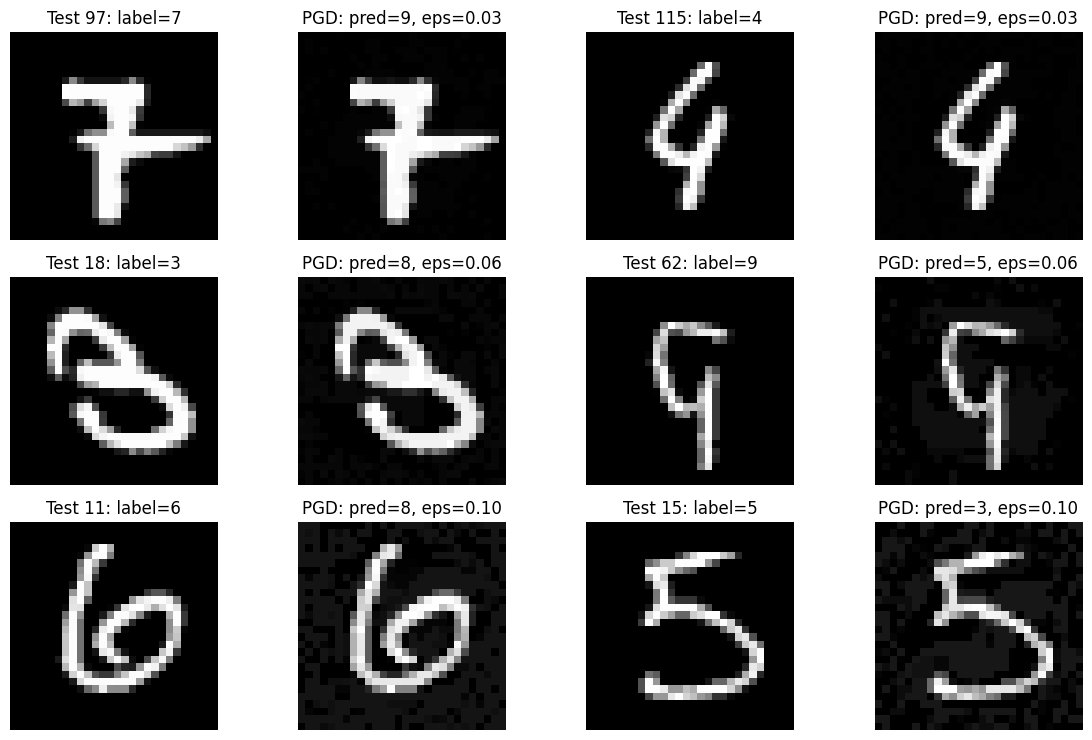

In [9]:
epsilons = sorted({item[-1] for item in examples})
fig, axes = plt.subplots(len(epsilons), 4, figsize=(12, 2.5 * len(epsilons)), squeeze=False)

for i, eps in enumerate(epsilons):
    row_examples = sorted([item for item in examples if item[-1] == eps], key=lambda item: item[0])[:2]
    for j, (index, x, adv, label, pred, _) in enumerate(row_examples):
        axes[i, 2*j].imshow(x.squeeze(), cmap='gray', vmin=0, vmax=1)
        axes[i, 2*j].set_title(f'Test {index}: label={label}')
        axes[i, 2*j+1].imshow(adv.squeeze(), cmap='gray', vmin=0, vmax=1)
        axes[i, 2*j+1].set_title(f'PGD: pred={pred}, eps={eps:.2f}')
    for ax in axes[i]:
        ax.axis('off')
fig.tight_layout()
plt.show()